## Chapter 10 - *p*-value Pitfalls and How to Avoid Them

In this chapter we will learn how to observe the Multiple Testing problem, to adjust *p*-values to counteract the effects of multiple testing, and observe the negative effects of Significance Chasing.

In [1]:
import numpy as np
from scipy.stats import ttest_ind
import seaborn as sns
from statsmodels.stats.multitest import multipletests

### Observing the Multiple Testing Problem

In order to observe the multiple testing problem, we're going to do a lot of *t*-tests where the null hypothesis is true, both sets of measurements come from the same distribution. We'll then save all of the *p*-values and see how many are less than 0.05, and thus, false positives. If things work as expected, we should get about 5% false positives.

<class 'function'>
<class 'numpy.ndarray'>
[0.98081668 0.33167739 0.41943775 0.81973924 0.48624052]


<Axes: ylabel='Count'>

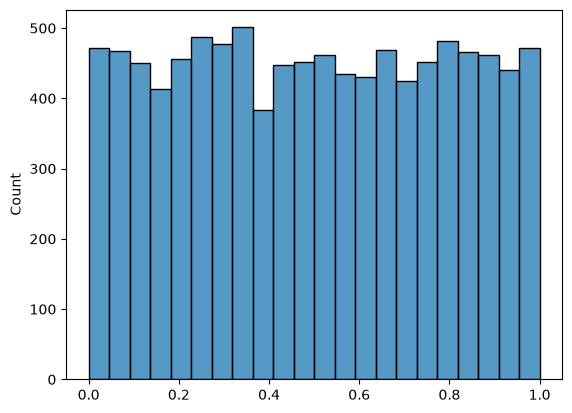

In [ ]:
np.random.seed(42)

pop_mean = 0
pop_sd = 1

num_rand_datasets = 10_000

num_datapoints = 3

p_values = np.empty(num_rand_datasets)

for i in range(num_rand_datasets):
    group_a = np.random.normal(loc=pop_mean, scale=pop_sd, size=num_datapoints)
    group_b = np.random.normal(loc=pop_mean, scale=pop_sd, size=num_datapoints)

    ## t-tests with equal variances = F-test
    results = ttest_ind(group_a, group_b, equal_var=True)
    p_values[i] = results.pvalue

sns.histplot(data=p_values)

Data

The histogram shows that *p*-values are (relativley) uniformly distributed between 0 and 1. This makes sense if, for whatever threshold we want to us is, *x*, the we should get *x* $\times 100$ false positives. For example, if the threshold is 0.05, like it is here, then we should get 5% false positives and thus, 5% of the *p*-values should be < 0.05. If, on the other hand, the threshold is 0.1, then we should get 10% false posiitves, and thus, 10% of the *p*-values should be < 0.10.

Now let's calculate the number of false poisitves, the number of *p*-values < 0.05.

In [6]:
num_false_positives = np.sum(p_values < 0.05)
num_false_positives

print(num_false_positives / num_rand_datasets)

0.0518


And we see that about 5% of the *p*-values resulted in false positives. So, things worked as expected and we got a bunch of false positives from multiple testing, even though we know that the Nul hypothesis is false.

### Adjusting *p*-values to compensate for multiple testing

What happens if we adjust those *p*-values to compensate for multiple testing? Since we created a bunch of *p*-values when we know that the Null Hypothesis is true, it should be interesting to see how many of these 500-ish remain < 0.05 after adjusting them for multiple testing. In this example, we will start by using the Holm correction.

In [7]:
## First, adjust the p-values with the Holm correction
adjusted_stuff = multipletests(p_values, method='holm')

## Adjusted stuff is a 'tuple', and the 2nd thing is an array
## of adjusted p-values
adjusted_stuff[1]

array([1., 1., 1., ..., 1., 1., 1.], shape=(10000,))

In [8]:
## Now, determine how many adjusted p-values are false positives
num_false_positives_Holm = np.sum(adjusted_stuff[1] < 0.05)
num_false_positives_Holm

np.int64(0)

And we see that, after adjusting the *p*-values with the Holm correction, there are no longer any false positives.

Now, let's see if the same thing happens when using the False Discovery Rate (FDR), to adjust the *p*-values.

In [9]:
adjusted_stuff = multipletests(p_values, method='fdr_bh')
adjusted_stuff[1]
num_false_positives_FDR = np.sum(adjusted_stuff[1] < 0.05)
num_false_positives_FDR

np.int64(0)

So, either way we adjust the *p*-values, we eliminate all the false positives. Now let's observe the negative effects of significance chasing.

### Observing the negative effects of significance chasing

Just like we did earlier when we wanted to observe the multiple testing problem, here we are going to do a lot of *t*-tests where the null hypothesis is true, both sets of measurements come from the same distribution. However, this time we will select thests where the *p*-values are close to 0.05, but still, greater than it. For those tests, we will add on additional measurement per group and save the *p*-value with all the others. If adding new data to the original tests have *p*-values close to 0.05 does not result in additional false positives, we should have about 5% of false positives in the end. If we have more than 5% false positives, then we will have seen the effects of significance chasing, and an increase of false positives – as a result of us adding drata to the tests that looked the most promising.

<Axes: ylabel='Count'>

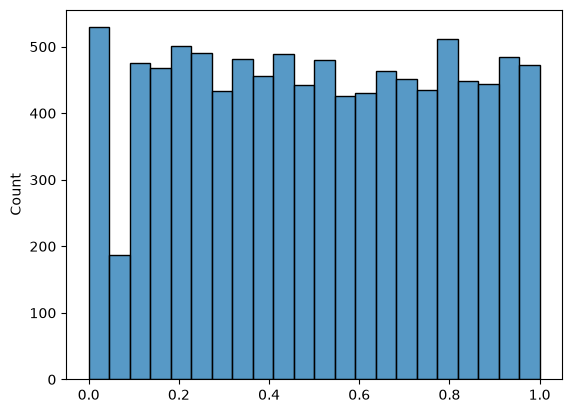

In [10]:
np.random.seed(42)

pop_mean = 0
pop_sd = 1

num_rand_datasets = 10_000

num_datapoints = 3

p_values = np.empty(num_rand_datasets)

for i in range(num_rand_datasets):

    group_a = np.random.normal(loc=pop_mean,scale=pop_sd,
                               size=num_datapoints)
    group_b = np.random.normal(loc=pop_mean,scale=pop_sd,
                               size=num_datapoints)
    results = ttest_ind(group_a, group_b, equal_var=True)

    if 0.05 < results.pvalue < 0.08:
        extra_a = np.random.normal(loc=pop_mean,scale=pop_sd,
                                   size=1)
        extra_b = np.random.normal(loc=pop_mean,scale=pop_sd,
                                   size=1)
        group_a = np.append(group_a, extra_a)
        group_b = np.append(group_b, extra_b)

        results = ttest_ind(group_a, group_b, equal_var=True)

    p_values[i] = results.pvalue

sns.histplot(data=p_values)

In this histogram, we can see that the second column has a lot fewer *p*-values in it than any of the other columns. This is because the *t*-tests associated with thte *p*-values in that bin were re-done with additional data. As a result, we have more than 500 *p*-values in the surrounding coulmns, including the first column, which suggests that we could have more than 500 false positives. So let's count the number of false positives.

In [12]:
num_false_positives = np.sum(p_values < 0.05)
num_false_positives
num_false_positives / num_rand_datasets

np.float64(0.0569)

And we see that, compared to the original illustration of the multiple testing problem, when we both expected and recieved 5.0% of false positives, when we added data to promising *t*-tests, we ended up with 5.7% false positives, and about 50-ish additional false positives.

So, the moral of the story is this. If a test looks promising, don't just add additional data existing measurements. Instead, do a proper power analysis and start over, collecting new data.